\
# 02 · Нулевая модель теплового взаимодействия океана и атмосферы

**Моделирование взаимодействия океана и атмосферы**

Простейшая связанная климатическая модель: три резервуара с температурами
$T_a$ (приземная атмосфера), $T_m$ (верхний квазиоднородный слой океана, ВКС)
и $T_d$ (глубинный слой), обменивающиеся теплом:

$$
\frac{dT_a}{dt} = \frac{-\lambda\,(T_a - T_m) - \lambda_a T_a + q}{c_a}, \qquad
\frac{dT_m}{dt} = \frac{-\lambda\,(T_m - T_a) - \lambda_{md}(T_m - T_d)}{c_m}, \qquad
\frac{dT_d}{dt} = \frac{-\lambda_{md}\,(T_d - T_m)}{c_d}
$$

| коэффициент | значение | смысл |
|---|---|---|
| $c_a,\ c_m,\ c_d$ | 0.45 / 10 / 100 | теплоёмкости резервуаров (время — годы) |
| $\lambda$ | 45 | теплообмен «атмосфера ↔ ВКС» |
| $\lambda_{md}$ | 2 | теплообмен «ВКС ↔ глубинный слой» |
| $\lambda_a$ | 2.4 | радиационное выхолаживание атмосферы |
| $q$ | 1 | внешний приток тепла |

Система линейная, с устойчивой матрицей оператора, поэтому:

- есть аналитическое стационарное решение $T_a = T_m = T_d = q/\lambda_a$ —
  численное решение можно **верифицировать**;
- времена релаксации мод = $-1/\operatorname{Re}\mu_i$ собственных чисел —
  их можно предсказать до расчёта.

Численные эксперименты лабораторной: (1) полная модель; (2) без обмена
«атмосфера–океан» ($\lambda=0$); (3) без обмена «ВКС–глубины»
($\lambda_{md}=0$). Интегратор — классический Рунге–Кутта 4-го порядка.

In [1]:
\
from pathlib import Path
import sys

ROOT = Path.cwd().parent
if str(ROOT / "src") not in sys.path:  # если пакет oahm не установлен
    sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.titlesize": 12,
    "axes.labelsize": 11,
    "legend.fontsize": 10,
})

FIG_DIR = ROOT / "figures"   # статичные иллюстрации для README
RES_DIR = ROOT / "results"   # анимации и обработанные данные
DATA_DIR = ROOT / "data"
FIG_DIR.mkdir(exist_ok=True)
RES_DIR.mkdir(exist_ok=True)


In [2]:
\
import oahm.box_model as bm

p0 = bm.BoxParams()

pd.DataFrame({
    "стационар [Ta, Tm, Td]": p0.steady_state,
}, index=["Ta", "Tm", "Td"]).T.round(3)

,Ta,Tm,Td
"стационар [Ta, Tm, Td]",0.417,0.417,0.417


\
## Три численных эксперимента

Интегрируем каждую конфигурацию на 100 лет с шагом 1/365 года
и накладываем аналитическое решение (пунктир) — визуально оно совпадает
с численным: это первая проверка корректности интегратора.

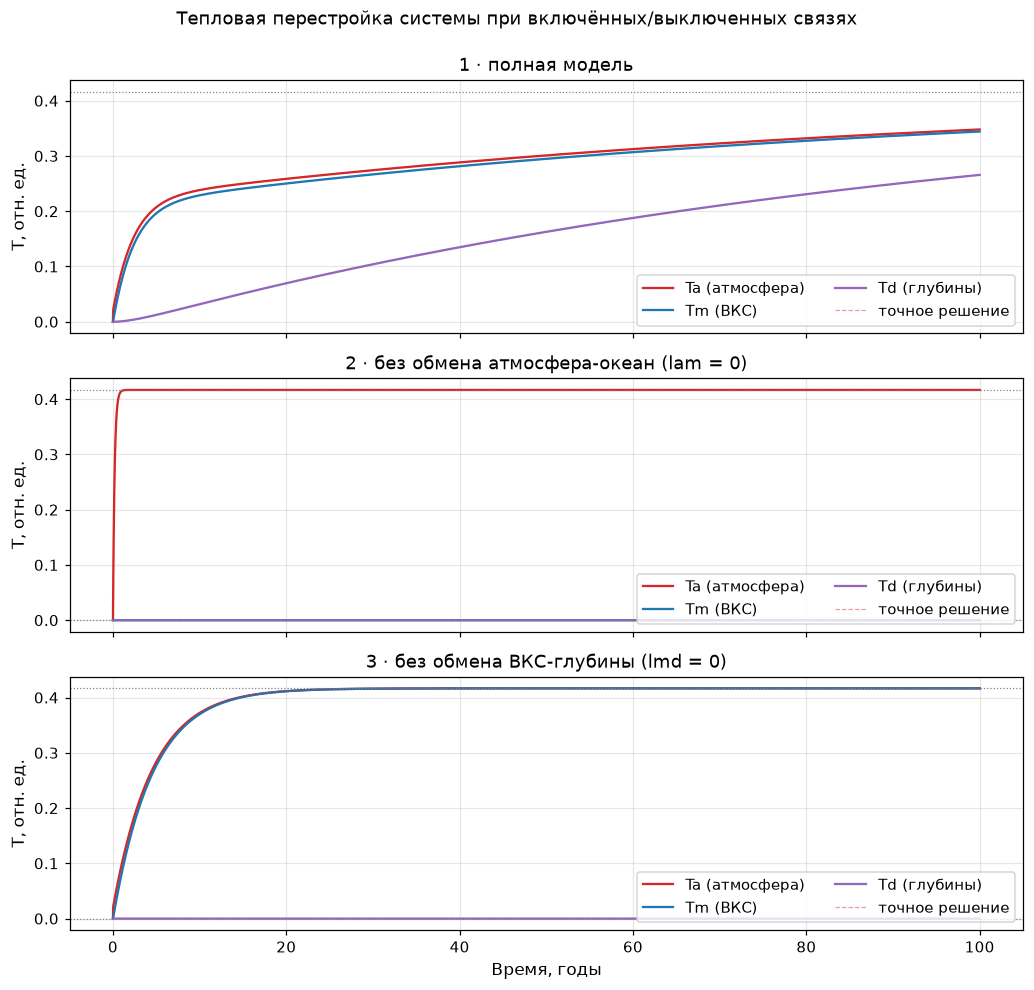

In [3]:
\
YEARS = 100
DT = 1 / 365

experiments = {
    "1 · полная модель": p0,
    "2 · без обмена атмосфера-океан (lam = 0)": bm.with_overrides(p0, lam=0.0),
    "3 · без обмена ВКС-глубины (lmd = 0)": bm.with_overrides(p0, lmd=0.0),
}

fig, axes = plt.subplots(3, 1, figsize=(9.5, 9), sharex=True)
for ax, (name, p) in zip(axes, experiments.items()):
    t, states = bm.integrate(p, years=YEARS, dt=DT)
    exact = bm.analytic_solution(p, t)
    assert np.allclose(states, exact, atol=2e-4), "RK4 разошёлся с аналитикой"

    ax.plot(t, states[:, 0], color="tab:red", lw=1.5, label="Ta (атмосфера)")
    ax.plot(t, states[:, 1], color="tab:blue", lw=1.5, label="Tm (ВКС)")
    ax.plot(t, states[:, 2], color="tab:purple", lw=1.5, label="Td (глубины)")
    for j, col in enumerate(("tab:red", "tab:blue", "tab:purple")):
        ax.plot(t, exact[:, j], "--", color=col, lw=0.8, alpha=0.45,
                label="точное решение" if j == 0 else None)
    for lvl in np.unique(np.round(p.steady_state, 6)):
        ax.axhline(lvl, color="grey", ls=":", lw=0.8)
    ax.set_ylabel("T, отн. ед.")
    ax.set_title(name)
    ax.legend(loc="lower right", ncols=2)

axes[-1].set_xlabel("Время, годы")
fig.suptitle("Тепловая перестройка системы при включённых/выключенных связях",
             y=0.995)
fig.tight_layout()
fig.savefig(FIG_DIR / "02_box_model_experiments.png", dpi=150,
            bbox_inches="tight")

\
Система выходит на стационар **с малым шагом** (РК4, шаг ~ сутки) на горизонте
в сотни лет — типичная жёсткость климатических моделей: быстрая атмосфера
подстраивается за ~месяц, а глубинный слой — за десятилетия. Времена
релаксации мод можно посчитать заранее по спектру оператора:

In [4]:
\
eigvals, _ = np.linalg.eig(bm.operator(p0))
timescales = np.sort(1.0 / np.abs(eigvals.real))

pd.DataFrame({
    "релаксация, лет": timescales,
    "релаксация, суток": timescales * 365.25,
    "процесс": ["быстрый обмен Ta<->Tm", "связка с глубинным слоем",
                "прогрев глубокого океана"],
}).round(2)

,"релаксация, лет","релаксация, суток",процесс
0,0.01,3.33,быстрый обмен Ta<->Tm
1,2.38,868.20,связка с глубинным слоем
2,96.08,35092.91,прогрев глубокого океана


\
## Верификация схем: фактический порядок точности

Ожидаемый порядок: Эйлер — 1, РК4 — 4. Считаем ошибку в момент $t = 10$ лет
относительно точного решения при измельчении шага; наклон линий на
лог-лог графике и есть фактический порядок.

rk4: ошибки [1.92e-12 1.18e-13 7.66e-15 5.30e-16 2.78e-17]
euler: ошибки [5.00e-05 2.50e-05 1.25e-05 6.26e-06 3.13e-06]


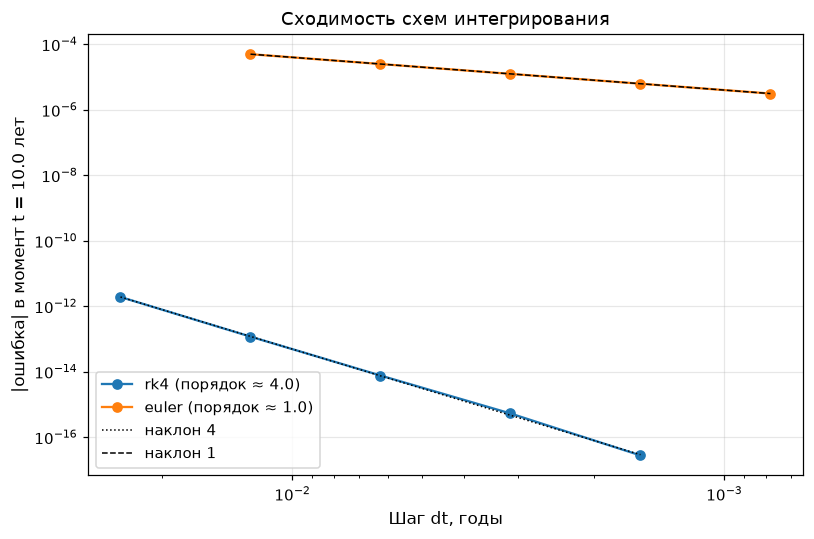

In [5]:
\
t_final = 10.0
# РК4 устойчив при lambda_max*dt <~ 2.8 (lambda_max ~ 105 1/год), поэтому dt < 1/40
dts_rk4 = 1 / np.array([40, 80, 160, 320, 640])
dts_euler = 1 / np.array([80, 160, 320, 640, 1280])  # Эйлер устойчив при dt < ~1/53

fig, ax = plt.subplots(figsize=(7.5, 5))
errors = {}
for scheme, dts, color in (("rk4", dts_rk4, "tab:blue"),
                           ("euler", dts_euler, "tab:orange")):
    err = bm.convergence_error(p0, dts, t_final=t_final, scheme=scheme)
    errors[scheme] = err
    order = np.log2(err[:-1] / err[1:]).mean()
    ax.loglog(dts, err, "o-", color=color, label=f"{scheme} (порядок ≈ {order:.1f})")
    err_str = np.array2string(err, formatter={"all": lambda val: f"{val:.2e}"})
    print(f"{scheme}: ошибки {err_str}")

ax.loglog(dts_rk4, errors["rk4"][0] * (dts_rk4 / dts_rk4[0]) ** 4,
          "k:", lw=1, label="наклон 4")
ax.loglog(dts_euler, errors["euler"][-1] * (dts_euler / dts_euler[-1]) ** 1,
          "k--", lw=1, label="наклон 1")
ax.invert_xaxis()
ax.set_xlabel("Шаг dt, годы")
ax.set_ylabel(f"|ошибка| в момент t = {t_final} лет")
ax.set_title("Сходимость схем интегрирования")
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "02_box_model_convergence.png", dpi=150, bbox_inches="tight")

\
## Выводы

1. Реализована боксовая модель, её точное (спектральное) решение и интеграторы
   Эйлера/РК4; численное решение совпадает с аналитическим на всём горизонте
   (assert в цикле экспериментов).
2. Связь с океаном определяет динамику приземной температуры: без неё
   ($\lambda=0$) атмосфера выходит на $q/\lambda_a$ мгновенно, а океан
   «замерзает» в начальном состоянии; без связи с глубинами поверхностный
   слой следует за атмосферой, и только полный набор связей даёт выход всей
   системы на $q/\lambda_a$.
3. Спектр оператора предсказывает времена релаксации (~месяц, ~десятилетие,
   ~полвека) — глубокий океан является «памятью» системы; фактический порядок
   точности схем (1 и 4) подтверждён численным экспериментом сходимости.